**Linear SVM + T0: preprocessed baseline (73 features)**

Train six C settings using the shared 24,000 training and 6,000 validation rows.
T0 uses shared preprocessing only, with no K-means, PCA or polynomial expansion.
The official test split is not loaded or scored.

Tables and figures retained below are from the recorded run. The cleaned notebook
has not been retrained; run cells from top to bottom to refresh the results.

**Linear SVM and regularization**

`LinearSVC` predicts attack when $f(z)=w^\top z+b>0$, where $z$ is the shared
preprocessed row. Scores are not probabilities. With $t_i=2y_i-1$, squared-hinge
loss is $\max(0,1-t_i f(z_i))^2$. The L2 objective, including liblinear's penalized
intercept at the retained `intercept_scaling=1`, is

$$\min_{w,b}\;\frac12(\lVert w\rVert_2^2+b^2)
+C\sum_i\max(0,1-t_i(w^\top z_i+b))^2.$$

Smaller C means stronger regularization; larger C prioritizes reducing margin
violations. All settings use the same zero decision threshold.

**1. Setup and shared splits**

`load_split()` reads the raw CSVs saved by `preprocessing.ipynb`, separates labels
and attack-type metadata, and excludes `id`, `label`, `attack_cat` and `is_ftp_login`
from inputs. Run that notebook first if the split files are missing.

In [ ]:
import sys
sys.path.append("..")  # import src/ from the notebook/ working directory

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import ConfusionMatrixDisplay

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
FIGS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

X_train, y_train, _ = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, "validation:", X_val.shape)

**2. T0 pipeline**

**Shared preprocessing → LinearSVC**. Preprocessing produces 35 categorical
indicators, 31 log1p-scaled numeric features and seven other scaled numeric
features. Each pipeline fits scaling and the classifier on training only.
Validation reuses those fitted parameters; no extra scaler is added.

Keep L2, squared-hinge loss, `dual="auto"`, `random_state=42` and the initial
5,000-iteration limit. The linear boundary retains the EDA's correlated and TTL
features; no new interactions or cluster distances are introduced.

In [ ]:
def build(C, max_iter=5000):
    return make_pipeline(
        build_preprocessor(),
        LinearSVC(C=C, dual="auto", max_iter=max_iter, random_state=RANDOM_STATE),
    )

**3. Regularization sweep**

We decide to use C with 6 different values (C = 0.001, 0.01, 0.1, 1, 10, 100) to better compare the model's performance at different penalty parameters.

`evaluate()` returns train/validation precision, recall, F1, FPR, fit time and
convergence status. Retain the existing retries at 10,000 then 20,000 iterations
only if a convergence warning occurs. `fit_time_s` describes the final attempt.
The table includes every C; `f1_gap` is train F1 minus validation F1.

In [ ]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {}

for value in GRID:
    for budget in [5000, 10000, 20000]:
        pipe = build(value, max_iter=budget)
        row = evaluate(pipe, "SVM", "T0", "C", value, X_train, y_train, X_val, y_val)
        if row["converged"]:
            break
    rows.append(row)
    fitted[value] = pipe
    print(f"C={value:g}: val F1={row['val_f1']:.4f}, converged={row['converged']}")

In [ ]:
results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
display(results.drop(columns=["model", "transformation", "param"]).round(4))

,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8587,0.9712,0.9115,0.1721,0.8611,0.9669,0.9109,0.1678,0.07,True,0.0005
1,0.010,0.8646,0.9697,0.9141,0.1634,0.8665,0.9643,0.9128,0.1599,0.09,True,0.0013
2,0.100,0.8719,0.9645,0.9158,0.1525,0.8734,0.9601,0.9147,0.1498,0.10,True,0.0012
3,1.000,0.8748,0.9617,0.9161,0.1482,0.8750,0.9569,0.9141,0.1471,0.17,True,0.0020
4,10.000,0.8758,0.9617,0.9167,0.1468,0.8750,0.9563,0.9138,0.1471,0.37,True,0.0029
5,100.000,0.8761,0.9614,0.9168,0.1463,0.8752,0.9563,0.9140,0.1467,0.39,True,0.0028


**4. Validation curve**

Left: training F1 (dashed) and validation F1 (solid). Right: validation precision,
recall and FPR. Moving right on the log-scaled C axis weakens regularization.
A widening gap with worsening validation can suggest overfitting; a small gap
alone does not prove underfitting.

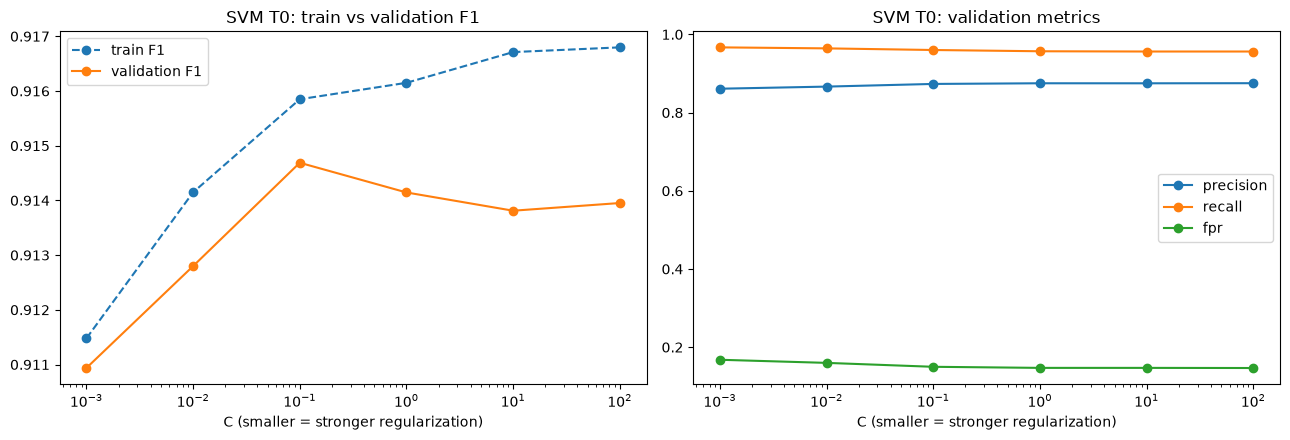

In [ ]:
plot_sweep(results, "SVM T0", FIGS / "curve_svm_t0.png")

**Recorded run:** validation F1 peaks at **C=0.1 (0.9147)**. Training F1 increases
slightly at larger C, but validation does not improve; the largest F1 gap is
0.0029. All six settings converged at the initial iteration limit. Larger C
reduces FPR but also reduces attack recall. Differences are small on this single
validation split and are not significance tests.

**5. Best setting and validation errors**

Choose the highest validation F1 among converged fits; exact ties favor the first
(smaller) C. Flagged fits remain in the results table. If none converge, increase
the iteration budget before selection. An edge winner may justify a wider grid.
Validation selects C, so the selected score is not an untouched test estimate.

In [ ]:
eligible = results[results["converged"]]
if eligible.empty:
    raise RuntimeError("No converged setting. Review optimization before selecting a model.")
best = eligible.loc[eligible["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"Best C={best['value']:g}: val F1={best['val_f1']:.4f}, "
      f"precision={best['val_precision']:.4f}, recall={best['val_recall']:.4f}, "
      f"FPR={best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("Best C is at the grid edge: consider extending it.")

The confusion matrix shows true labels in rows and predictions in columns.
Top-right is false alarms; bottom-left is missed attacks. FPR is the fraction of
normal flows flagged as attacks, not the fraction of all flows.

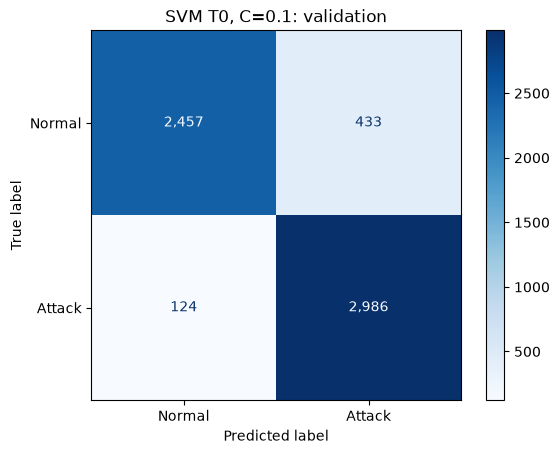

In [ ]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",",
)
plt.title(f"SVM T0, C={best['value']:g}: validation")
plt.savefig(FIGS / "confusion_svm_t0.png", dpi=150, bbox_inches="tight")
plt.show()

`attack_recall()` reports caught and missed validation attacks by type.
`attack_cat` is metadata only. Check both recall and absolute misses; rare types
such as Worms have uncertain estimates even at 100% recall.

In [ ]:
display(attack_recall(y_val, pred_val, cat_val))

,rows,caught,missed,recall
type,,,,
Fuzzers,899,801,98,0.891
Analysis,89,86,3,0.966
DoS,212,206,6,0.972
Backdoor,85,83,2,0.976
Exploits,1105,1094,11,0.990
Generic,233,231,2,0.991
Reconnaissance,419,417,2,0.995
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


**Recorded errors and limitations:** the selected model makes 433 false alarms
and misses 124 attacks; Fuzzers account for 98 misses. This is consistent with
the EDA's overlapping Fuzzers/Normal features, but does not establish each error's
cause. TTL shortcuts may limit transfer to real traffic.

There is no validation fitting in this pipeline. However, shared feature/category
choices came from EDA on the full training file, including validation candidates;
validation is a fitting holdout, not wholly unseen exploratory data. Retained
interpretations describe the recorded run and should be refreshed after rerunning.

**6. Save the results**

Save all six settings to `results/svm_t0.csv` with the shared metric schema and
`model="SVM"`, `transformation="T0"`. The validation curve and confusion matrix
use T0-specific figure files; the official test remains reserved for final evaluation.

In [ ]:
results.to_csv(RESULTS / "svm_t0.csv", index=False)
print("Saved", len(results), "rows to", RESULTS / "svm_t0.csv")